In [1]:
import sys
from src.E8 import E8 as E8_ricardo
from src.E10 import E10 as E10_ricardo
#from src.E9 import E9 as E9_ricardo
#from src.E10 import E10
import numpy as np
import time
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
"""
plt.rcParams.update({
    "mathtext.fontset": "cm",        # Computer Modern for math
    "font.family": "serif",
    "font.serif": ["cmr10"],         # Computer Modern for normal text
    "axes.formatter.use_mathtext": True,  # needed so cmr10 draws minus signs and 10^x ticks correctly
})
"""
plt.rcParams.update({
    "mathtext.fontset": "cm",
    "font.family": "serif",
    "font.serif": ["cmr10"],
    "axes.formatter.use_mathtext": True,
    # sizes for the printed figure
    "font.size": 8,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "axes.linewidth": 0.6,
})

def do_cov_sub_plot(ax, normalize, title, ax_index, C_order, ell_range, ell_p_range):
        
        l_min = ell_range[0]
        l_max = ell_range[1]
        lp_min = ell_p_range[0]
        lp_max = ell_p_range[1]
        C_order = np.where(np.abs(C_order) < 1e-12, 1e-12, np.abs(C_order))

        ell_to_s_map = np.array([l * (l+1) - l - l_min**2  for l in range(l_min, l_max+1)])
        ellp_to_s_map = np.array([l * (l+1) - l - lp_min**2  for l in range(lp_min, lp_max+1)])

        axim = ax.imshow(C_order.T, cmap='inferno', norm=LogNorm(), origin='lower',  interpolation = 'nearest')

        if lp_max > 50 or l_max > 50:
            ax.set_title(str(ax_index+5), weight='bold', fontsize='30')
        else:
            #ax.set_title(str(ax_index+1), weight='bold', fontsize='20')
            ax.set_title(rf'{title}', fontsize='30')


        if ax_index == 0 or ax_index == 3 or ax_index == 6:
             ax.set_ylabel(r"$\ell'$", fontsize=35)

             ax.set_yticks(ellp_to_s_map-0.5)
             ax.tick_params(axis='y', labelsize=18)
             ax.set_yticklabels(np.arange(lp_min, lp_max+1))
             ax.tick_params(which='major', length=10, width=3, labelsize=20)

        else:
             ax.set_yticks(ellp_to_s_map-0.5)
             ax.set_yticklabels([])          
             ax.tick_params(which='major', length=10, width=3, labelsize=20)   

        if ax_index == 6 or ax_index == 7 or ax_index == 8:
            ax.set_xlabel(r"$\ell $", fontsize=35)

            ax.set_xticks(ell_to_s_map-0.5)
            ax.tick_params(axis='x', labelsize=18)
            ax.set_xticklabels(np.arange(l_min, l_max+1))
            ax.tick_params(which='major', length=10, width=3, labelsize=20)

        else:
            ax.set_xticks(ell_to_s_map-0.5)
            ax.set_xticklabels([])
            ax.tick_params(which='major', length=10, width=3, labelsize=20)
        
        if normalize:
            axim.set_clim(1e-8, 1e0)
        else:
            axim.set_clim(1e-14, 1e2)

        return axim


# Set parameter file
#import parameter_files.default as parameter_file
#def run_topology(topology, LAx, LAy, L1y = 0.1, L2x = 0.1, L2z = 0.1, l_max = 10, l_min = 2, x0 = np.array([0.0, 0.0, 0.0]), l_range= np.array([[2,2]]), lp_range= np.array([[2,2]])):
def run_topology(topology, LAx, LAy, LBx, LBz, LCy, l_max = 10, l_min = 2, x0 = np.array([0.0, 0.0, 0.0]), l_range= np.array([[2,2]]), lp_range= np.array([[2,2]])):
  if topology == 'E8':
    import parameter_files.default_E8 as parameter_file
  elif topology == 'E10':
    import parameter_files.default_E8 as parameter_file

  param = parameter_file.parameter
  param['topology'] = topology
  param['LAx'] = LAx
  param['LAy'] = LAy
  param['LBx'] = LBx
  param['LBz'] = LBz
  param['LCy'] = LCy
#  param['L1y'] = L1y
#  param['L2x'] = L2x
#  param['L2z'] = L2z

  param['l_max'] = l_max
  param['l_min'] = l_min
  param['node'] = 1
  param['x0'] = x0

  if param['topology'] == 'E8':
    a = E8_ricardo(param=param, make_run_folder=True)
  elif param['topology'] == 'E10':
    a = E10_ricardo(param=param, make_run_folder=True)
  else:
    exit()

  c_ell = a.calculate_c_lmlpmp(
    plot_param={
      'l_ranges':l_range,
      'lp_ranges': lp_range,
    }
  )
 
  return c_ell


In [2]:
l_max = 5
L_circle = 1

#LAx, LAy, LBx, LBz, LCy
c_ell_untilted = run_topology(topology = 'E8', LAx = L_circle, LAy = 0, LBx = 0.7, LBz = 1.0, LCy = 1.4, 
              l_max = l_max, x0= np.array([0.0, 0.0, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

Running - E8 l_max=5_LAx_27649_LAy_0_LBx_19354_LBz_27649_LCy_38709_x_0.00_y_0.00_z_0.00
Running {'topology': 'E8', 'LAx': 1, 'LAy': 0, 'LBx': 0.7, 'LBz': 1.0, 'LCy': 1.4, 'x0': array([0., 0., 0.]), 'c_l_accuracy': 0.99, 'l_max': 5, 'l_min': 2, 'node': 1}
Shape of transfer function from CAMB: (3, 599, 6454)

Finding k_max as a function of ell


100%|██████████| 4/4 [00:00<00:00, 10.15it/s]


Done. k_max for ell_max = 0.01102416508743576
E7 Final num of elements: 1356585 Minimum k_amp 8.115772094424329e-05 n_x_max 98 n_z_max 98
Time to get list of k, phi, theta: 21.655893802642822 seconds
Getting repeated theta and k elements
Ratio of unique theta: 0.734457479627152
Ratio of unique |k|: 0.05340837470560267
Time to get unique k and theta: 0.20932507514953613 seconds

Getting transfer functions


100%|██████████| 72453/72453 [00:03<00:00, 21827.81it/s] 


Size of transfer function: 3.32 MB. 


Getting transfer functions


...

Size of transfer function: 3.32 MB. 


Getting transfer functions


100%|██████████| 72453/72453 [00:02<00:00, 25123.32it/s]


Size of transfer function: 3.32 MB. 


Getting Wigner_d matrices!


100%|██████████| 10/10 [00:37<00:00,  3.77s/it]


The Wigner_d metrices array is 136.83 MB 


**************
Done with all preprocessing
**************

Time to pre-process with l_max=5 and accuracy=0.99: 116.65556621551514 seconds

Calculating covariance matrix
Size of integrand: 119.4 MB.
Time to get Correlation functions: 0:0:24


In [4]:
l_max = 5
L_circle = 0.73321

#c_ell_tilted = run_topology(topology = 'E8', LAx = L_circle, LAy = 0, L1y = 1.4, L2x = 0.7, L2z = 1, 
#             l_max = l_max, x0= np.array([-0.1, 0.34, 0.0], dtype=np.float64), 
#             l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

c_ell_tilted = run_topology(topology = 'E8', LAx = L_circle, LAy = 0, LBx = 0.7, LBz = 1.0, LCy = 1.4, 
              l_max = l_max, x0= np.array([-0.1, 0.34, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

Running - E8 l_max=5_LAx_20273_LAy_0_LBx_19354_LBz_27649_LCy_38709_x_-0.10_y_0.34_z_0.00
Running {'topology': 'E8', 'LAx': 0.73321, 'LAy': 0, 'LBx': 0.7, 'LBz': 1.0, 'LCy': 1.4, 'x0': array([-0.1 ,  0.34,  0.  ]), 'c_l_accuracy': 0.99, 'l_max': 5, 'l_min': 2, 'node': 1}
Making run folder: runs/E8_LAx_0.73_LAy_0.00_LBx_0.70_LBz_1.00_LCy_1.40_x_-0.10_y_0.34_z_0.00_l_max_5/
Shape of transfer function from CAMB: (3, 599, 6454)

Finding k_max as a function of ell


100%|██████████| 4/4 [00:00<00:00, 17.61it/s]


Done. k_max for ell_max = 0.01102416508743576
E8 Final num of elements: 501461 Minimum k_amp 0.00015496352930530216 n_x_max 72 n_z_max 98
Time to get list of k, phi, theta: 7.4505250453948975 seconds
Getting repeated theta and k elements
Ratio of unique theta: 0.8150663760491843
Ratio of unique |k|: 0.14555269502513654
Time to get unique k and theta: 0.06968808174133301 seconds

Getting transfer functions


100%|██████████| 72989/72989 [00:02<00:00, 28713.45it/s]


Size of transfer function: 3.34 MB. 


Getting transfer functions


...

Size of transfer function: 3.34 MB. 


Getting transfer functions


100%|██████████| 72989/72989 [00:02<00:00, 29846.66it/s]


Size of transfer function: 3.34 MB. 


Getting Wigner_d matrices!


100%|██████████| 408724/408724 [00:11<00:00, 36562.92it/s] 


The Wigner_d metrices array is 112.26 MB 


**************
Done with all preprocessing
**************

Time to pre-process with l_max=5 and accuracy=0.99: 67.02813816070557 seconds

Calculating covariance matrix
Size of integrand: 120.28 MB.
Time to get Correlation functions: 0:0:13


<Figure size 640x480 with 0 Axes>

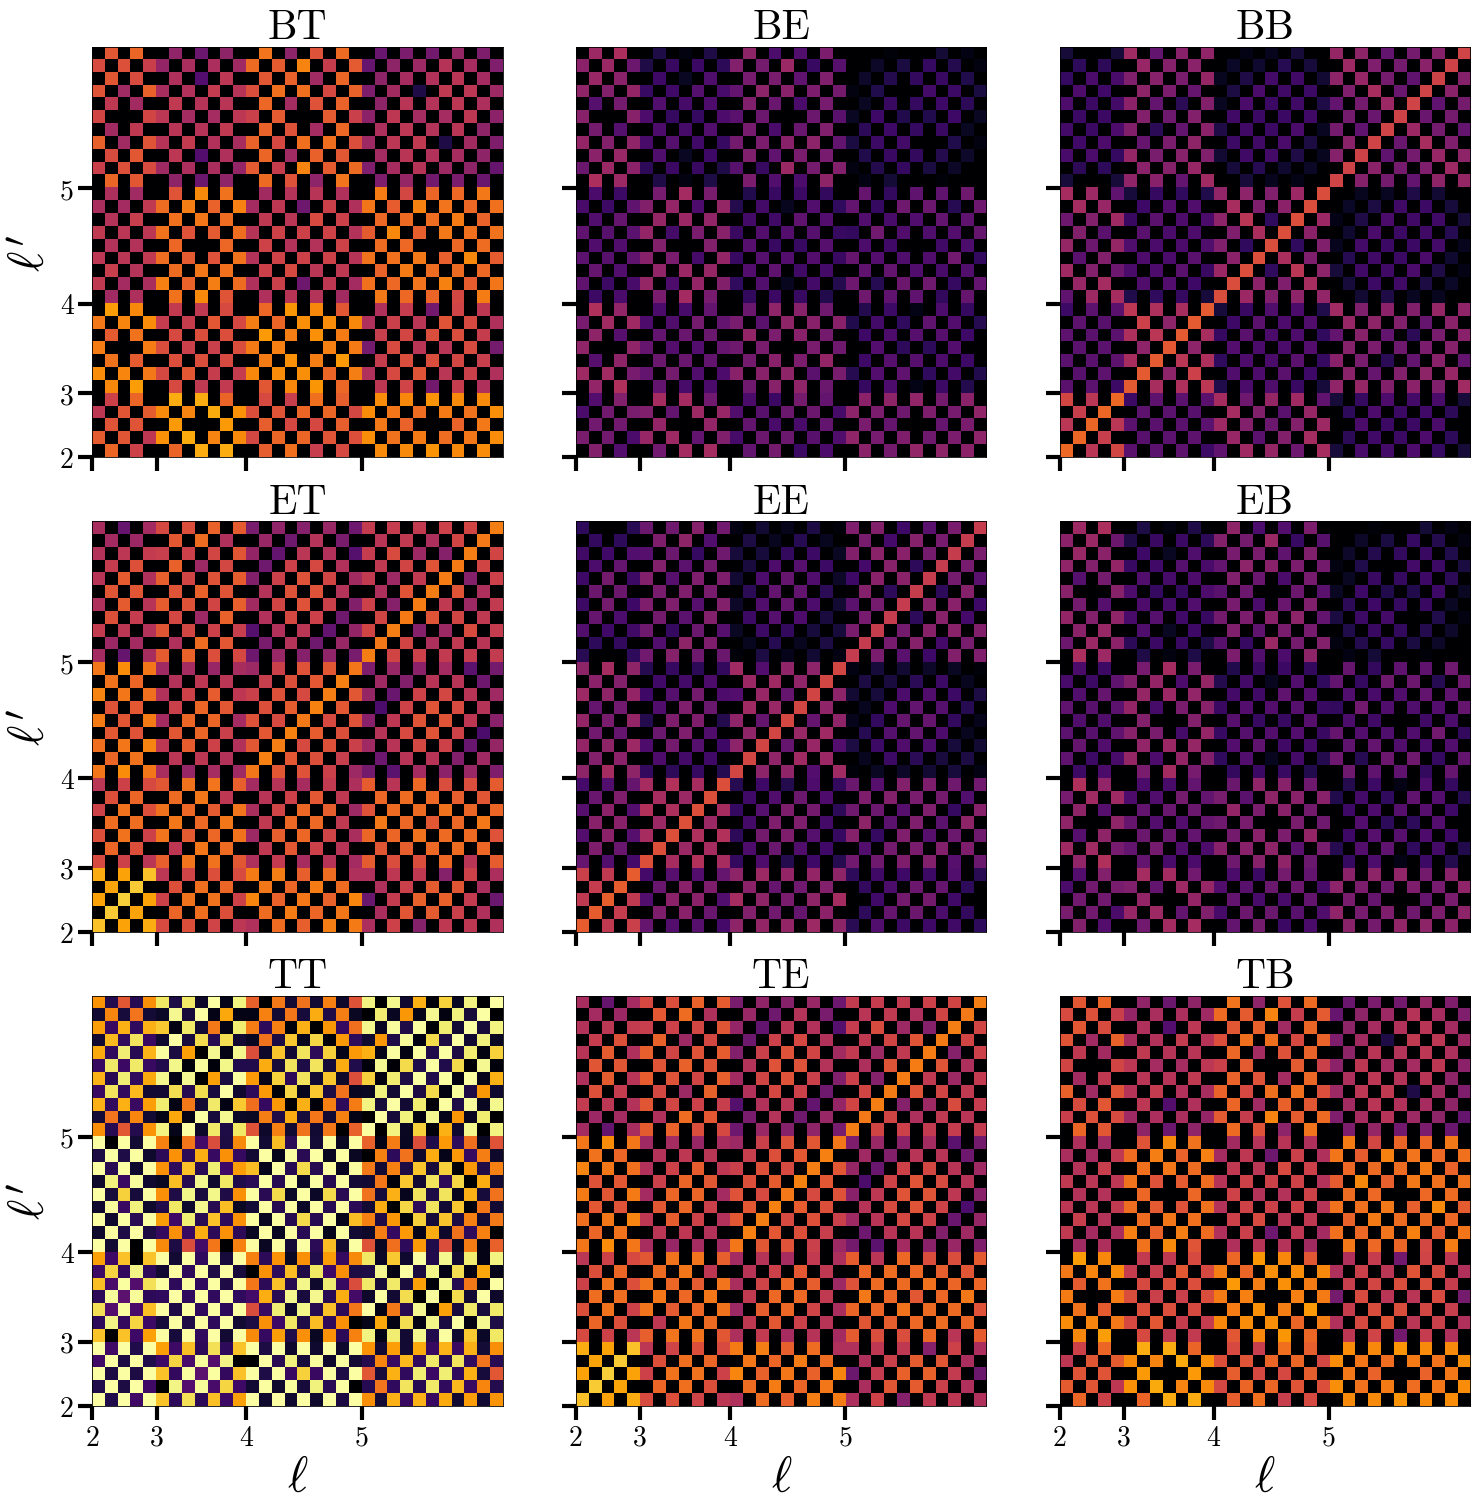

<Figure size 640x480 with 0 Axes>

In [3]:
fig, ax = plt.subplots(3,3, figsize=(15,15), layout='constrained')
im = do_cov_sub_plot(ax[0,0], normalize=True, title = r'BT',  ax_index=0, C_order=c_ell_untilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,1], normalize=True, title = r'BE', ax_index=1, C_order=c_ell_untilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,2], normalize=True, title = r'BB', ax_index=2, C_order=c_ell_untilted[2], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,0], normalize=True, title = r'ET', ax_index=3, C_order=c_ell_untilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,1], normalize=True, title = r'EE', ax_index=4, C_order=c_ell_untilted[1], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,2], normalize=True, title = r'EB', ax_index=5, C_order=c_ell_untilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,0], normalize=True, title = r'TT', ax_index=6, C_order=c_ell_untilted[0], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,1], normalize=True, title = r'TE', ax_index=7, C_order=c_ell_untilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,2], normalize=True, title = r'TB', ax_index=8, C_order=c_ell_untilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
plt.savefig('plots_E8_left.pdf', bbox_inches='tight', dpi=300)
plt.figure()

<Figure size 640x480 with 0 Axes>

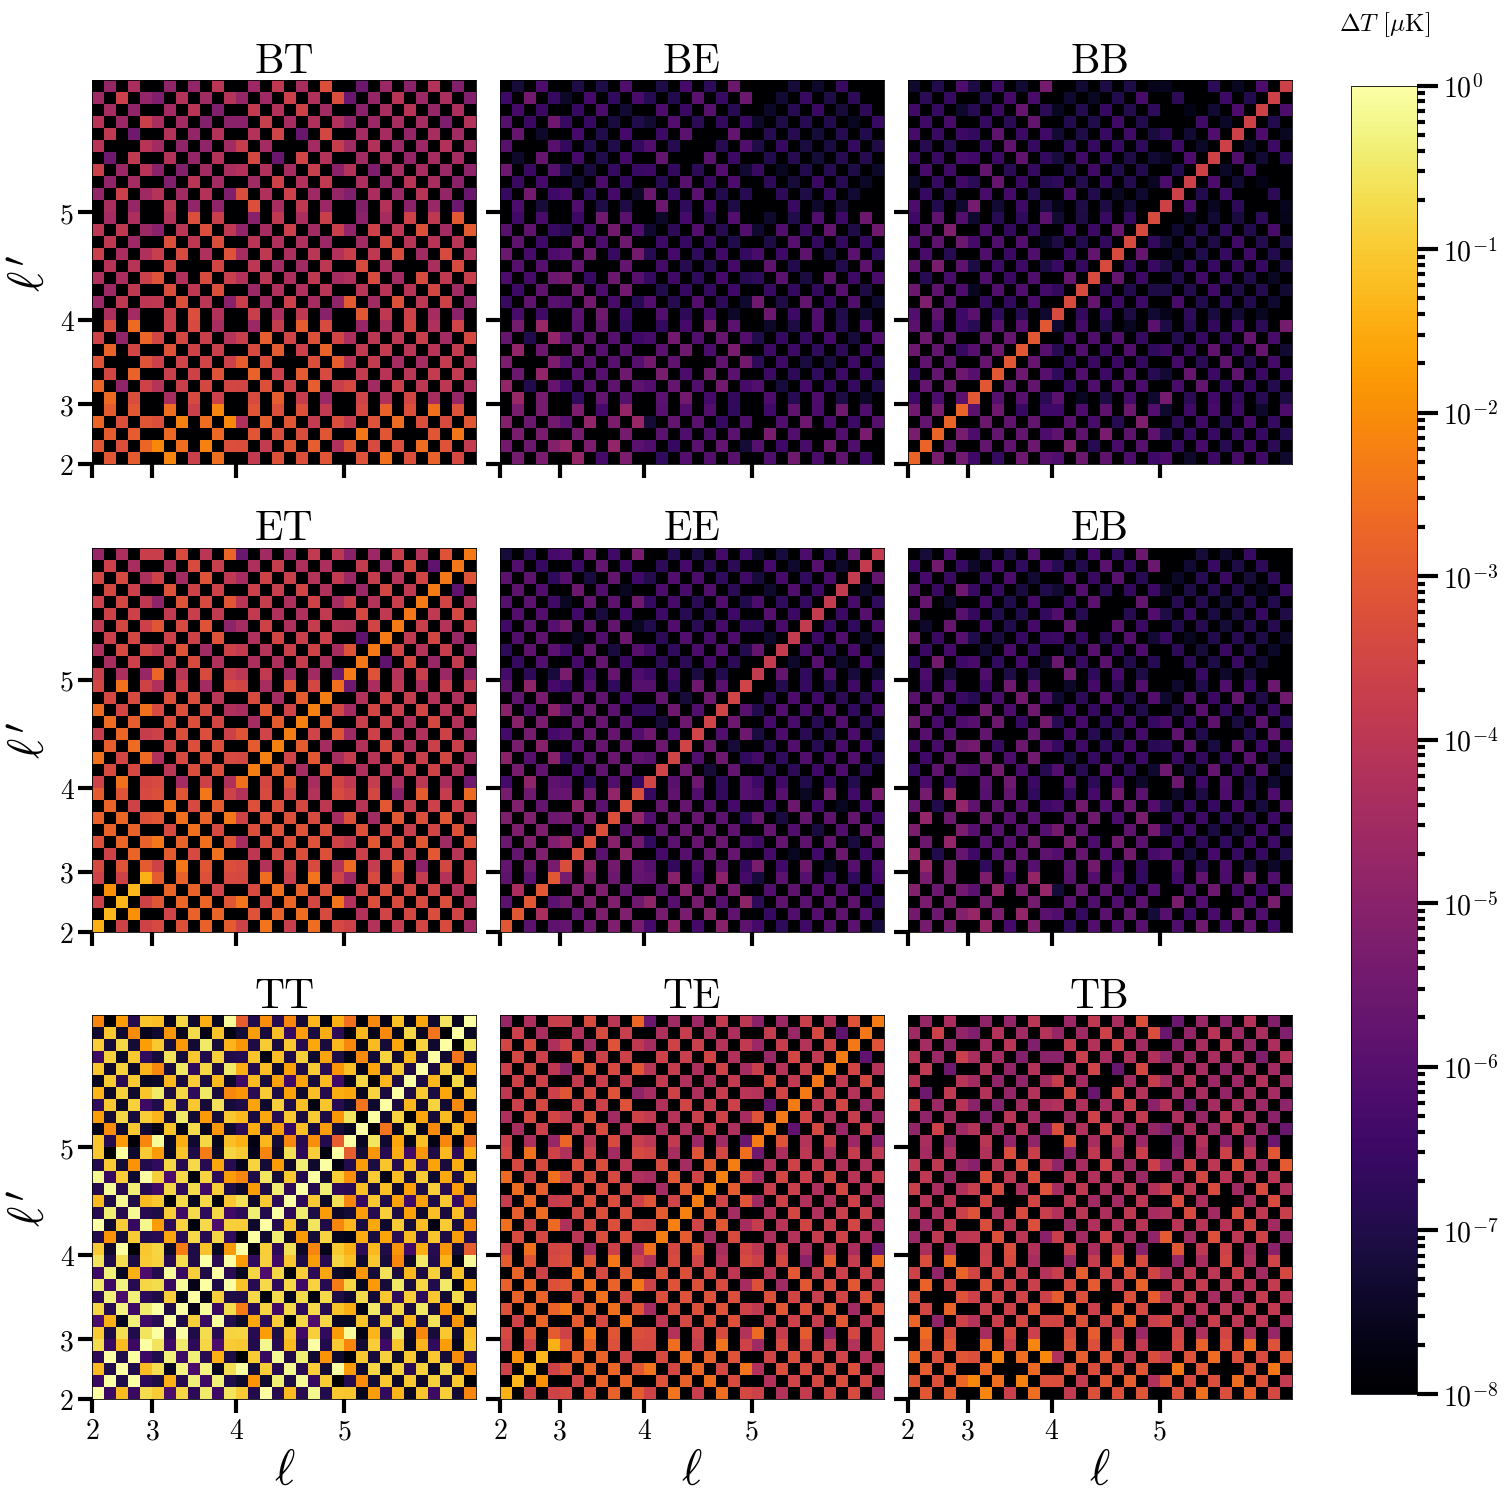

<Figure size 640x480 with 0 Axes>

In [5]:
fig, ax = plt.subplots(3,3, figsize=(15,15), layout='constrained')
im = do_cov_sub_plot(ax[0,0], normalize=True, title = 'BT',  ax_index=0, C_order=c_ell_tilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,1], normalize=True, title = r'BE', ax_index=1, C_order=c_ell_tilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,2], normalize=True, title = 'BB', ax_index=2, C_order=c_ell_tilted[2], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,0], normalize=True, title = 'ET', ax_index=3, C_order=c_ell_tilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,1], normalize=True, title = 'EE', ax_index=4, C_order=c_ell_tilted[1], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,2], normalize=True, title = 'EB', ax_index=5, C_order=c_ell_tilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,0], normalize=True, title = 'TT', ax_index=6, C_order=c_ell_tilted[0], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,1], normalize=True, title = 'TE', ax_index=7, C_order=c_ell_tilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,2], normalize=True, title = 'TB', ax_index=8, C_order=c_ell_tilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))

cbar = fig.colorbar(im, ax=ax, location='right', shrink=0.95)
cbar.ax.set_title(r"$\Delta T$ [$\mu$K]", fontsize=18, pad=40)
#cbar.set_label(r"$\Delta T$ [$\mu$K]", fontsize=18)
cbar.ax.tick_params(which='major', length=15, width=3, labelsize=20)
cbar.ax.tick_params(which='minor', length=6, width=3)

plt.savefig('plots_E8_right.pdf', bbox_inches='tight', dpi=300)
plt.figure()

In [7]:
l_max = 5
L_circle = 1



#c_ell_E10_untilted = run_topology(topology = 'E10', LAx = L_circle, LAy = 0, L1y = 1.2, L2x = 0.7, L2z = 1, 
#              l_max = l_max, x0= np.array([0.0, 0.0, 0.0], dtype=np.float64), 
#              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

c_ell_E10_untilted = run_topology(topology = 'E10', LAx = L_circle, LAy = 0, LBx = 0.7, LBz = 1.0, LCy = 1.4, 
              l_max = l_max, x0= np.array([0.0, 0.0, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

Running - E10 l_max=5_LAx_27649_LAy_0_LBx_19354_LBz_27649_LCy_38709_x_0.00_y_0.00_z_0.00
Running {'topology': 'E10', 'LAx': 1, 'LAy': 0, 'LBx': 0.7, 'LBz': 1.0, 'LCy': 1.4, 'x0': array([0., 0., 0.]), 'c_l_accuracy': 0.99, 'l_max': 5, 'l_min': 2, 'node': 1}
Making run folder: runs/E10_LAx_1.00_LAy_0.00_LBx_0.70_LBz_1.00_LCy_1.40_x_0.00_y_0.00_z_0.00_l_max_5/
Shape of transfer function from CAMB: (3, 599, 6454)

Finding k_max as a function of ell


100%|██████████| 4/4 [00:00<00:00, 21.09it/s]


Done. k_max for ell_max = 0.01102416508743576
E7 Final num of elements: 674630 Minimum k_amp 0.00019813124687042034 n_x_max 98 n_z_max 98
Time to get list of k, phi, theta: 9.976098775863647 seconds
Getting repeated theta and k elements
Ratio of unique theta: 0.7778989964869633
Ratio of unique |k|: 0.08646665579651068
Time to get unique k and theta: 0.09811186790466309 seconds

Getting transfer functions


100%|██████████| 58333/58333 [00:02<00:00, 20154.48it/s]


Size of transfer function: 2.67 MB. 


Getting transfer functions


...

Size of transfer function: 2.67 MB. 


Getting transfer functions


100%|██████████| 58333/58333 [00:02<00:00, 24787.46it/s]


Size of transfer function: 2.67 MB. 


Getting Wigner_d matrices!


100%|██████████| 524794/524794 [00:18<00:00, 28241.49it/s] 


The Wigner_d metrices array is 144.14 MB 


**************
Done with all preprocessing
**************

Time to pre-process with l_max=5 and accuracy=0.99: 83.84328699111938 seconds

Calculating covariance matrix
Size of integrand: 96.13 MB.
Time to get Correlation functions: 0:0:18


In [8]:
l_max = 5
L_circle = 0.73321

#c_ell_E10_tilted = run_topology(topology = 'E10', LAx = L_circle, LAy = 0, L1y = 1.4, L2x = 0.7, L2z = 1, 
#             l_max = l_max, x0= np.array([-0.1, 0.34, 0.0], dtype=np.float64), 
#             l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

c_ell_E10_tilted = run_topology(topology = 'E10', LAx = L_circle, LAy = 0, LBx = 0.7, LBz = 1.0, LCy = 1.4, 
              l_max = l_max, x0= np.array([-0.1, 0.34, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

Running - E10 l_max=5_LAx_20273_LAy_0_LBx_19354_LBz_27649_LCy_38709_x_-0.10_y_0.34_z_0.00
Running {'topology': 'E10', 'LAx': 0.73321, 'LAy': 0, 'LBx': 0.7, 'LBz': 1.0, 'LCy': 1.4, 'x0': array([-0.1 ,  0.34,  0.  ]), 'c_l_accuracy': 0.99, 'l_max': 5, 'l_min': 2, 'node': 1}
Making run folder: runs/E10_LAx_0.73_LAy_0.00_LBx_0.70_LBz_1.00_LCy_1.40_x_-0.10_y_0.34_z_0.00_l_max_5/
Shape of transfer function from CAMB: (3, 599, 6454)

Finding k_max as a function of ell


100%|██████████| 4/4 [00:00<00:00, 24.81it/s]

Done. k_max for ell_max = 0.01102416508743576


E7 Final num of elements: 496049 Minimum k_amp 0.00019813124687042034 n_x_max 72 n_z_max 98
Time to get list of k, phi, theta: 7.266013145446777 seconds
Getting repeated theta and k elements
Ratio of unique theta: 0.8079101056548849
Ratio of unique |k|: 0.14535660791575025
Time to get unique k and theta: 0.07089686393737793 seconds

Getting transfer functions


100%|██████████| 72104/72104 [00:02<00:00, 30250.33it/s]


...

Size of transfer function: 3.3 MB. 


Getting transfer functions


100%|██████████| 72104/72104 [00:02<00:00, 25084.48it/s]


Size of transfer function: 3.3 MB. 


Getting Wigner_d matrices!


100%|██████████| 400763/400763 [00:12<00:00, 31242.20it/s] 


The Wigner_d metrices array is 110.07 MB 


**************
Done with all preprocessing
**************

Time to pre-process with l_max=5 and accuracy=0.99: 74.39160394668579 seconds

Calculating covariance matrix
Size of integrand: 118.82 MB.
Time to get Correlation functions: 0:0:15


<Figure size 640x480 with 0 Axes>

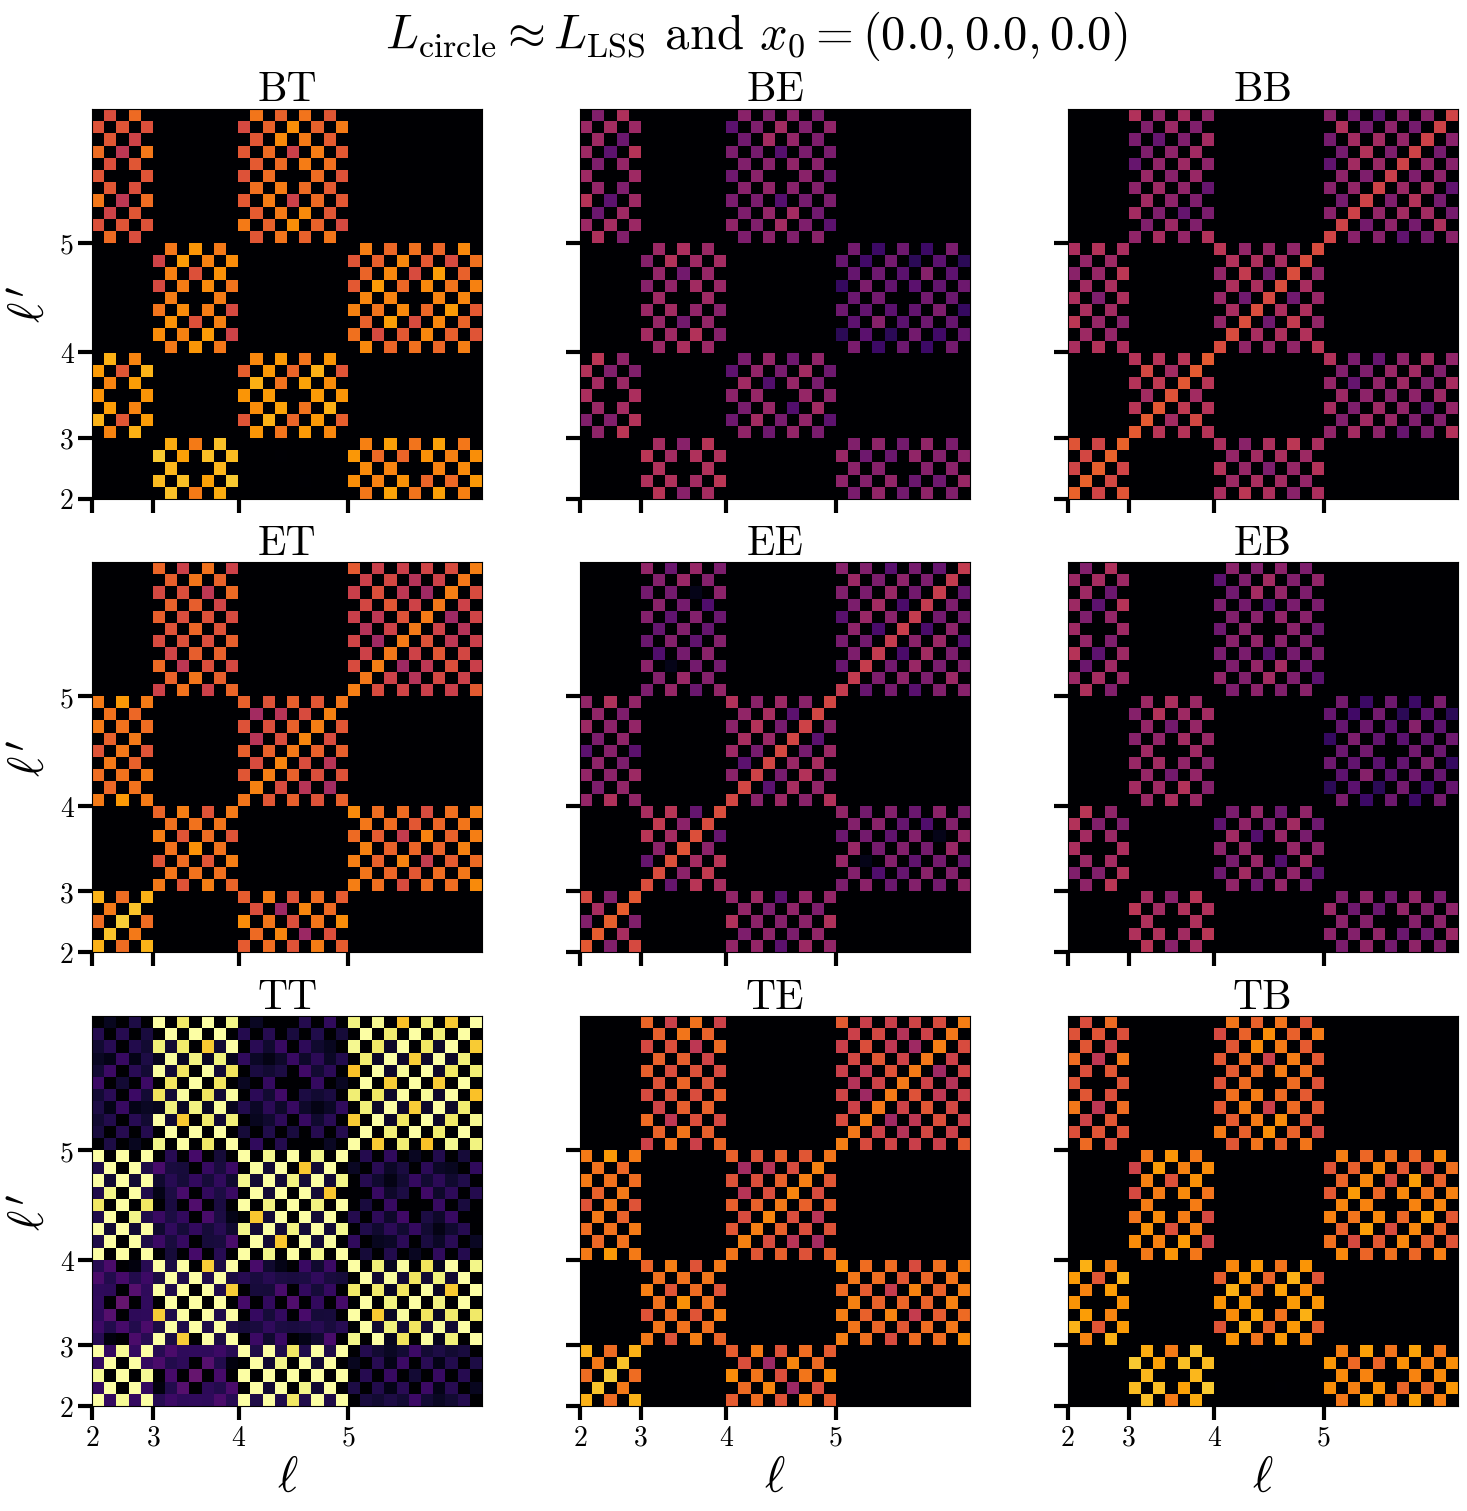

<Figure size 640x480 with 0 Axes>

In [49]:
fig, ax = plt.subplots(3,3, figsize=(15,15), layout='constrained')
im = do_cov_sub_plot(ax[0,0], normalize=True, title = r'BT',  ax_index=0, C_order=c_ell_E10_untilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,1], normalize=True, title = r'BE', ax_index=1, C_order=c_ell_E10_untilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,2], normalize=True, title = r'BB', ax_index=2, C_order=c_ell_E10_untilted[2], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,0], normalize=True, title = r'ET', ax_index=3, C_order=c_ell_E10_untilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,1], normalize=True, title = r'EE', ax_index=4, C_order=c_ell_E10_untilted[1], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,2], normalize=True, title = r'EB', ax_index=5, C_order=c_ell_E10_untilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,0], normalize=True, title = r'TT', ax_index=6, C_order=c_ell_E10_untilted[0], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,1], normalize=True, title = r'TE', ax_index=7, C_order=c_ell_E10_untilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,2], normalize=True, title = r'TB', ax_index=8, C_order=c_ell_E10_untilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))

fig.suptitle(r'$L_{\text{circle}} \approx L_{\text{LSS}}$ and $x_0 = (0.0, 0.0, 0.0)$', fontweight='bold', fontsize=35)
plt.savefig('plots_E10_left.pdf', bbox_inches='tight', dpi=300)
plt.figure()

<Figure size 640x480 with 0 Axes>

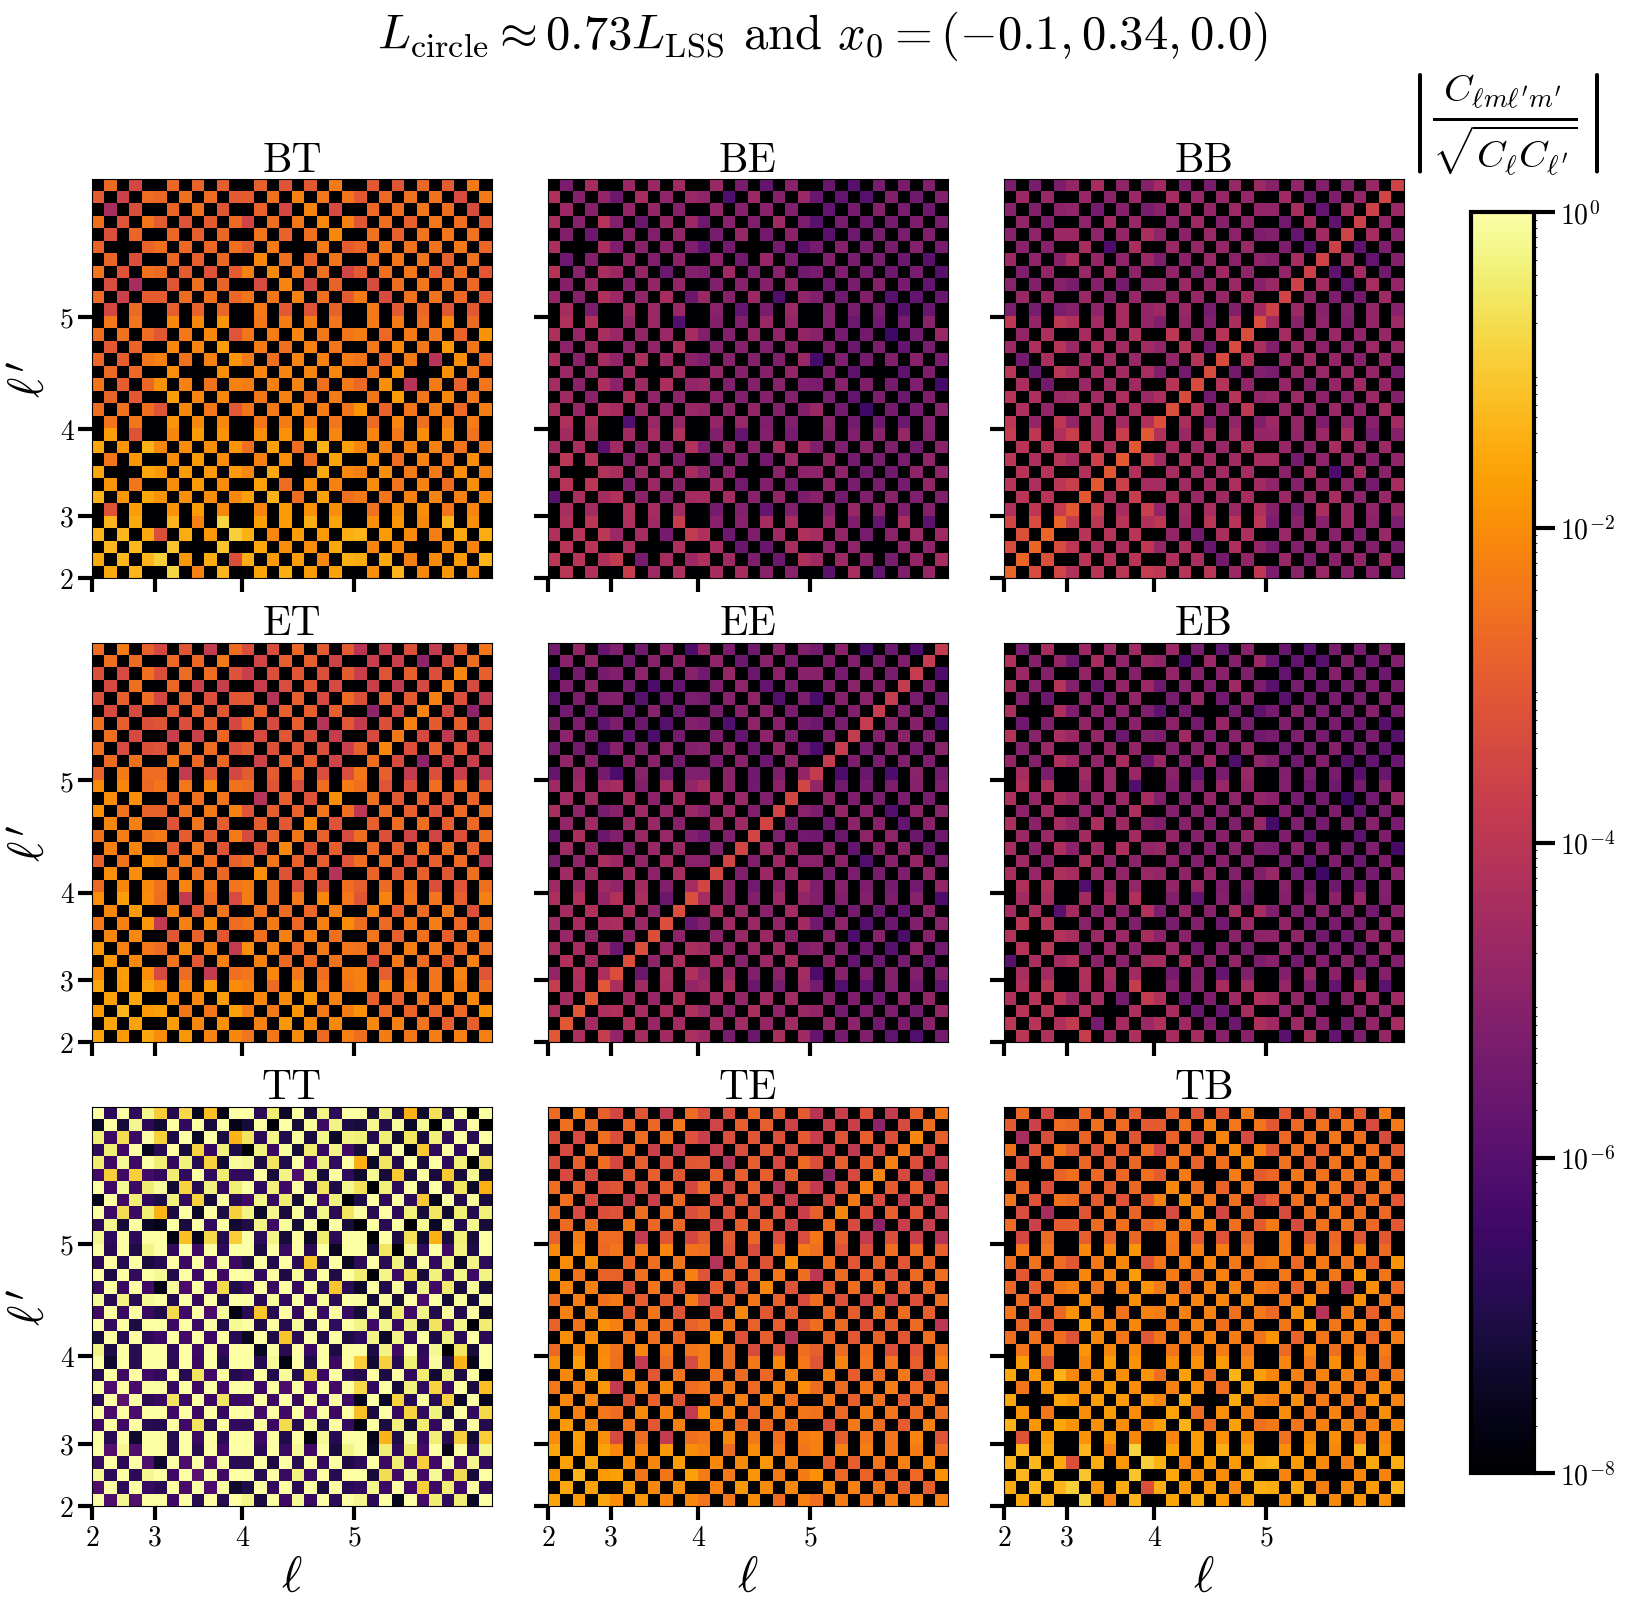

<Figure size 640x480 with 0 Axes>

In [48]:
fig, ax = plt.subplots(3,3, figsize=(16,16), layout='constrained')
im = do_cov_sub_plot(ax[0,0], normalize=True, title = 'BT',  ax_index=0, C_order=c_ell_E10_tilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,1], normalize=True, title = 'BE', ax_index=1, C_order=c_ell_E10_tilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,2], normalize=True, title = 'BB', ax_index=2, C_order=c_ell_E10_tilted[2], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,0], normalize=True, title = 'ET', ax_index=3, C_order=c_ell_E10_tilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,1], normalize=True, title = 'EE', ax_index=4, C_order=c_ell_E10_tilted[1], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,2], normalize=True, title = 'EB', ax_index=5, C_order=c_ell_E10_tilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,0], normalize=True, title = 'TT', ax_index=6, C_order=c_ell_E10_tilted[0], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,1], normalize=True, title = 'TE', ax_index=7, C_order=c_ell_E10_tilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,2], normalize=True, title = 'TB', ax_index=8, C_order=c_ell_E10_tilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))

cbar = fig.colorbar(im, ax=ax, location='right', shrink=0.95)
cbar.ax.set_title(r"$\left| \frac{C_{\ell m \ell' m'}}{\sqrt{C_{\ell}C_{\ell'}}} \right|$", fontsize=40, pad=60)
#cbar.set_label(r"$\Delta T$ [$\mu$K]", fontsize=18)
cbar.set_ticks([1e0, 1e-2, 1e-4, 1e-6, 1e-8])
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(3)  
cbar.ax.tick_params(which='major', length=15, width=3, labelsize=20)
#cbar.ax.tick_params(which='minor', length=6, width=3)

fig.suptitle(r'$L_{\text{circle}} \approx 0.73 L_{\text{LSS}}$ and $x_0 = (-0.1, 0.34, 0.0)$', fontweight='bold', fontsize=35)
plt.savefig('plots_E10_right.pdf', bbox_inches='tight', dpi=300)
plt.figure()

<Figure size 640x480 with 0 Axes>

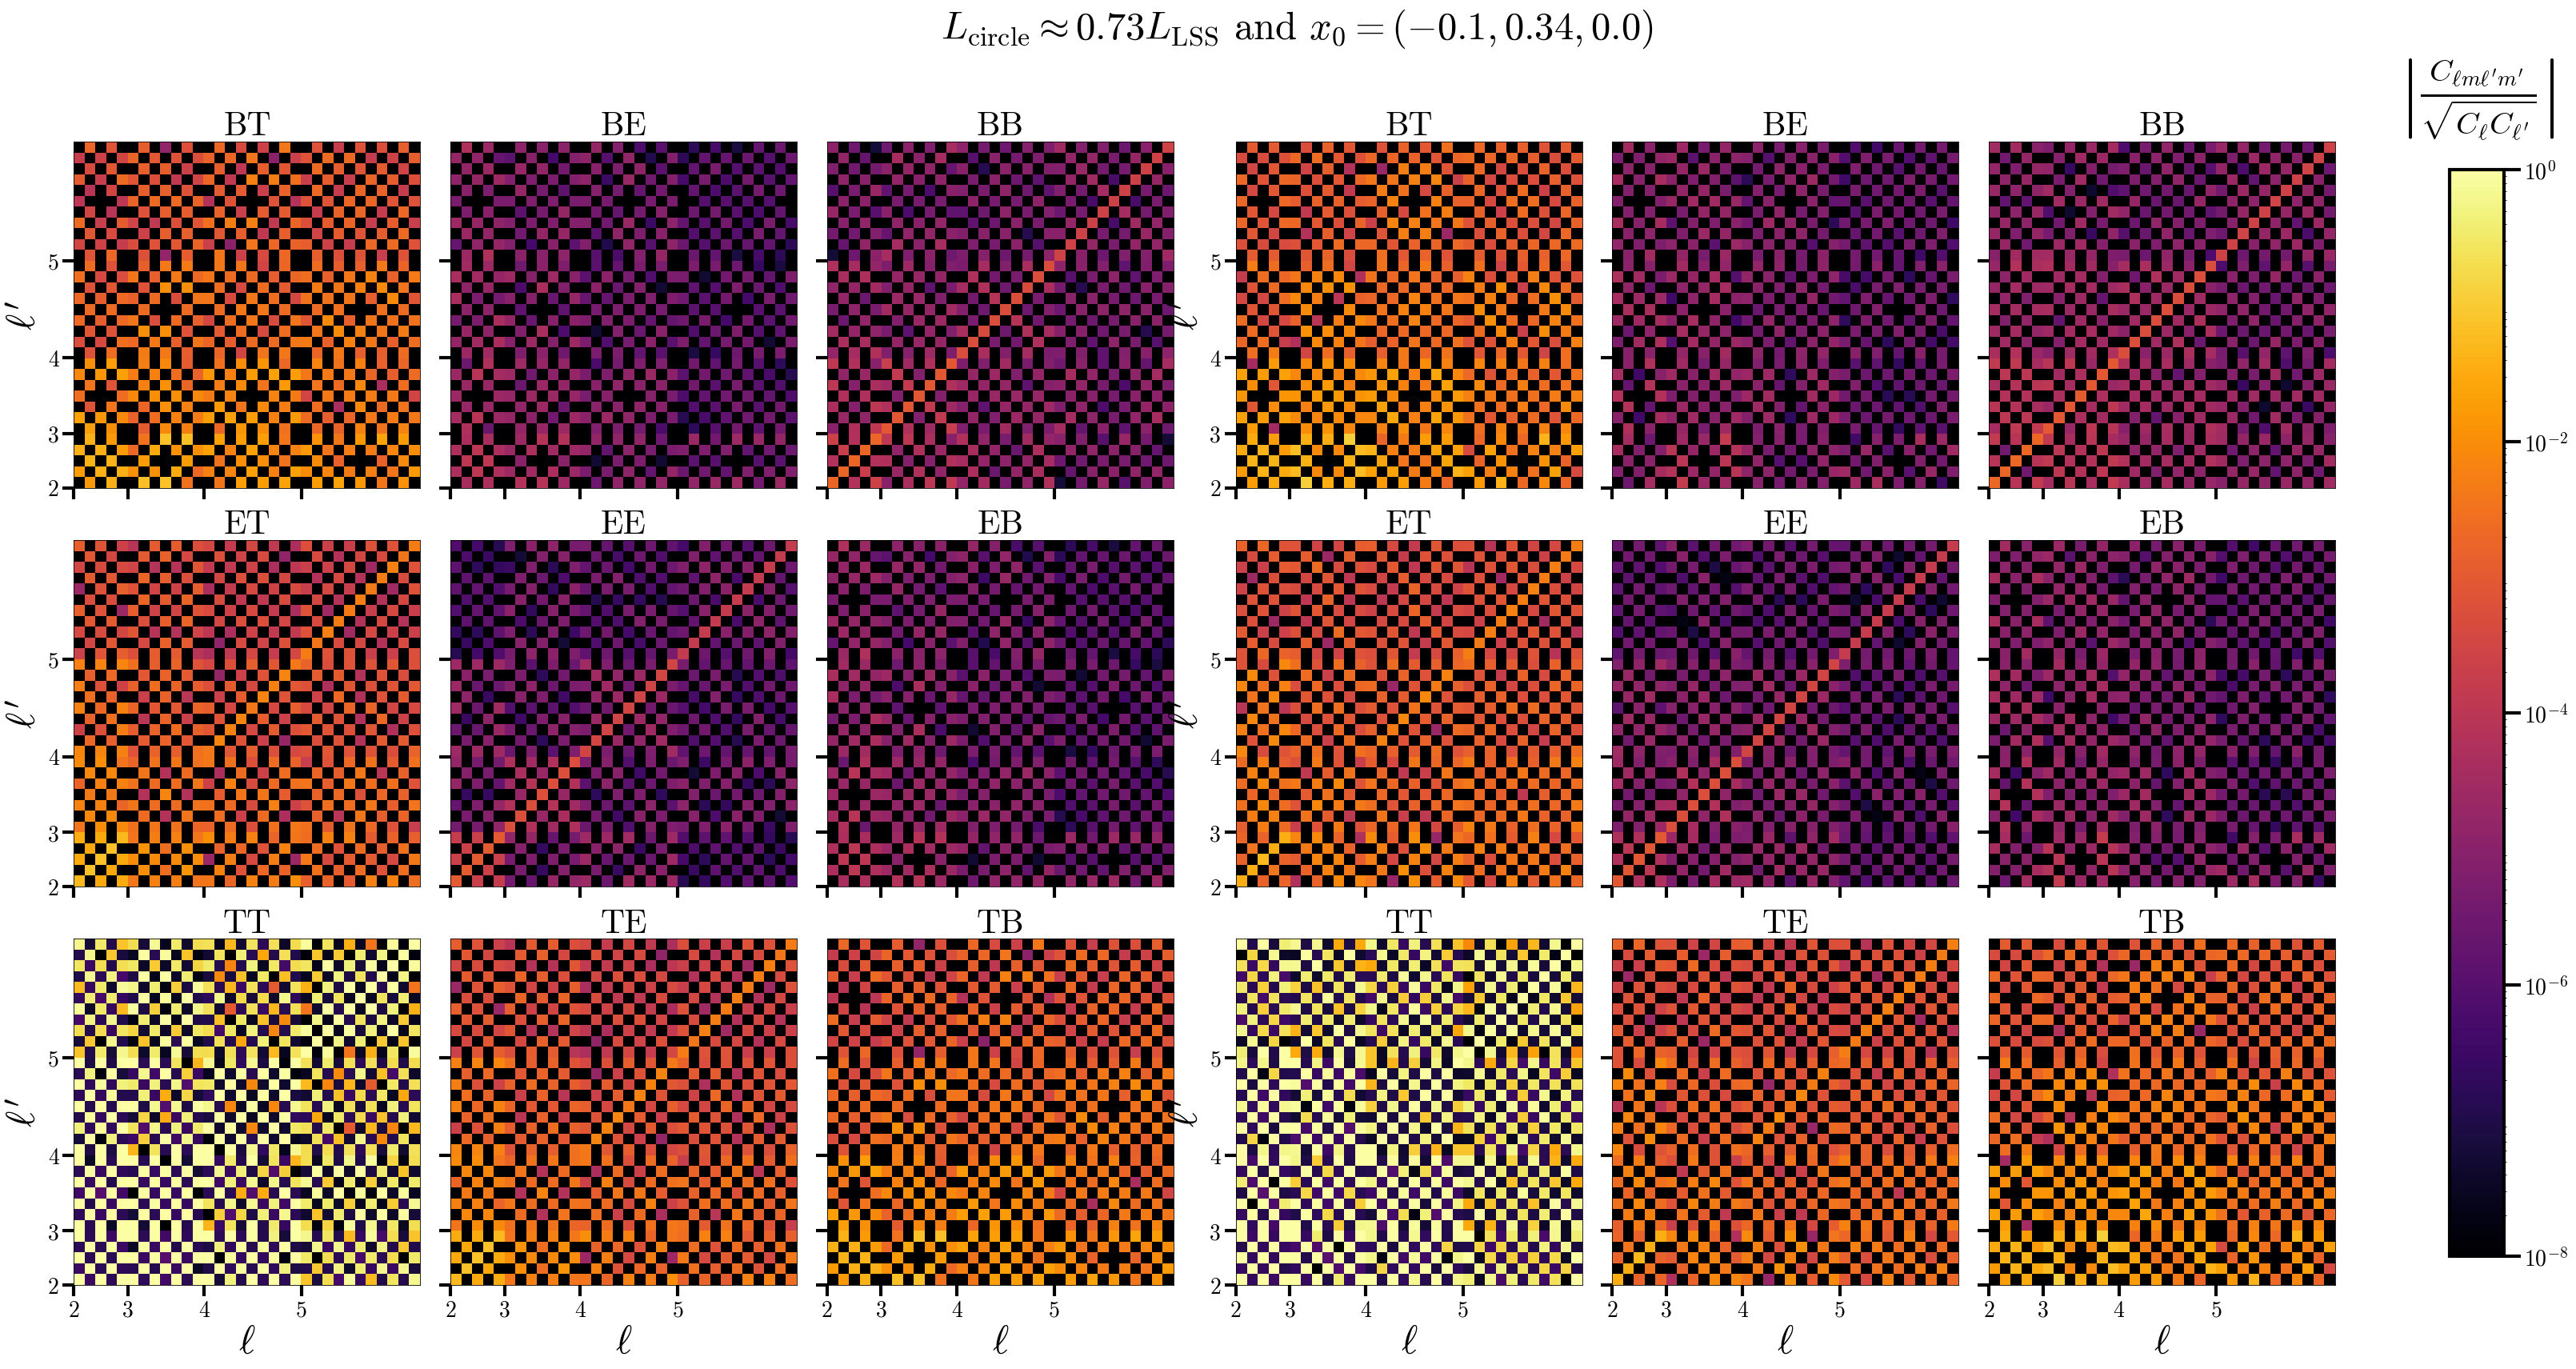

<Figure size 640x480 with 0 Axes>

In [9]:
fig, ax = plt.subplots(3,6, figsize=(32,17), layout='constrained')

im = do_cov_sub_plot(ax[0,0], normalize=True, title = 'BT',  ax_index=0, C_order=c_ell_E10_untilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,1], normalize=True, title = 'BE', ax_index=1, C_order=c_ell_E10_untilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,2], normalize=True, title = 'BB', ax_index=2, C_order=c_ell_E10_untilted[2], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,0], normalize=True, title = 'ET', ax_index=3, C_order=c_ell_E10_untilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,1], normalize=True, title = 'EE', ax_index=4, C_order=c_ell_E10_untilted[1], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,2], normalize=True, title = 'EB', ax_index=5, C_order=c_ell_E10_untilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,0], normalize=True, title = 'TT', ax_index=6, C_order=c_ell_E10_untilted[0], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,1], normalize=True, title = 'TE', ax_index=7, C_order=c_ell_E10_untilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,2], normalize=True, title = 'TB', ax_index=8, C_order=c_ell_E10_untilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))


im = do_cov_sub_plot(ax[0,3], normalize=True, title = 'BT',  ax_index=0, C_order=c_ell_E10_tilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,4], normalize=True, title = 'BE', ax_index=1, C_order=c_ell_E10_tilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[0,5], normalize=True, title = 'BB', ax_index=2, C_order=c_ell_E10_tilted[2], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,3], normalize=True, title = 'ET', ax_index=3, C_order=c_ell_E10_tilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,4], normalize=True, title = 'EE', ax_index=4, C_order=c_ell_E10_tilted[1], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[1,5], normalize=True, title = 'EB', ax_index=5, C_order=c_ell_E10_tilted[4], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,3], normalize=True, title = 'TT', ax_index=6, C_order=c_ell_E10_tilted[0], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,4], normalize=True, title = 'TE', ax_index=7, C_order=c_ell_E10_tilted[3], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))
do_cov_sub_plot(ax[2,5], normalize=True, title = 'TB', ax_index=8, C_order=c_ell_E10_tilted[5], ell_range = np.array([2,l_max]), ell_p_range = np.array([2,l_max]))

cbar = fig.colorbar(im, ax=ax, location='right', shrink=0.95)
cbar.ax.set_title(r"$\left| \frac{C_{\ell m \ell' m'}}{\sqrt{C_{\ell}C_{\ell'}}} \right|$", fontsize=40, pad=60)
#cbar.set_label(r"$\Delta T$ [$\mu$K]", fontsize=18)
cbar.set_ticks([1e0, 1e-2, 1e-4, 1e-6, 1e-8])
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(3)  
cbar.ax.tick_params(which='major', length=15, width=3, labelsize=20)
#cbar.ax.tick_params(which='minor', length=6, width=3)

fig.suptitle(r'$L_{\text{circle}} \approx 0.73 L_{\text{LSS}}$ and $x_0 = (-0.1, 0.34, 0.0)$', fontweight='bold', fontsize=35)
plt.savefig('plots_E10_right.pdf', bbox_inches='tight', dpi=300)
plt.figure()

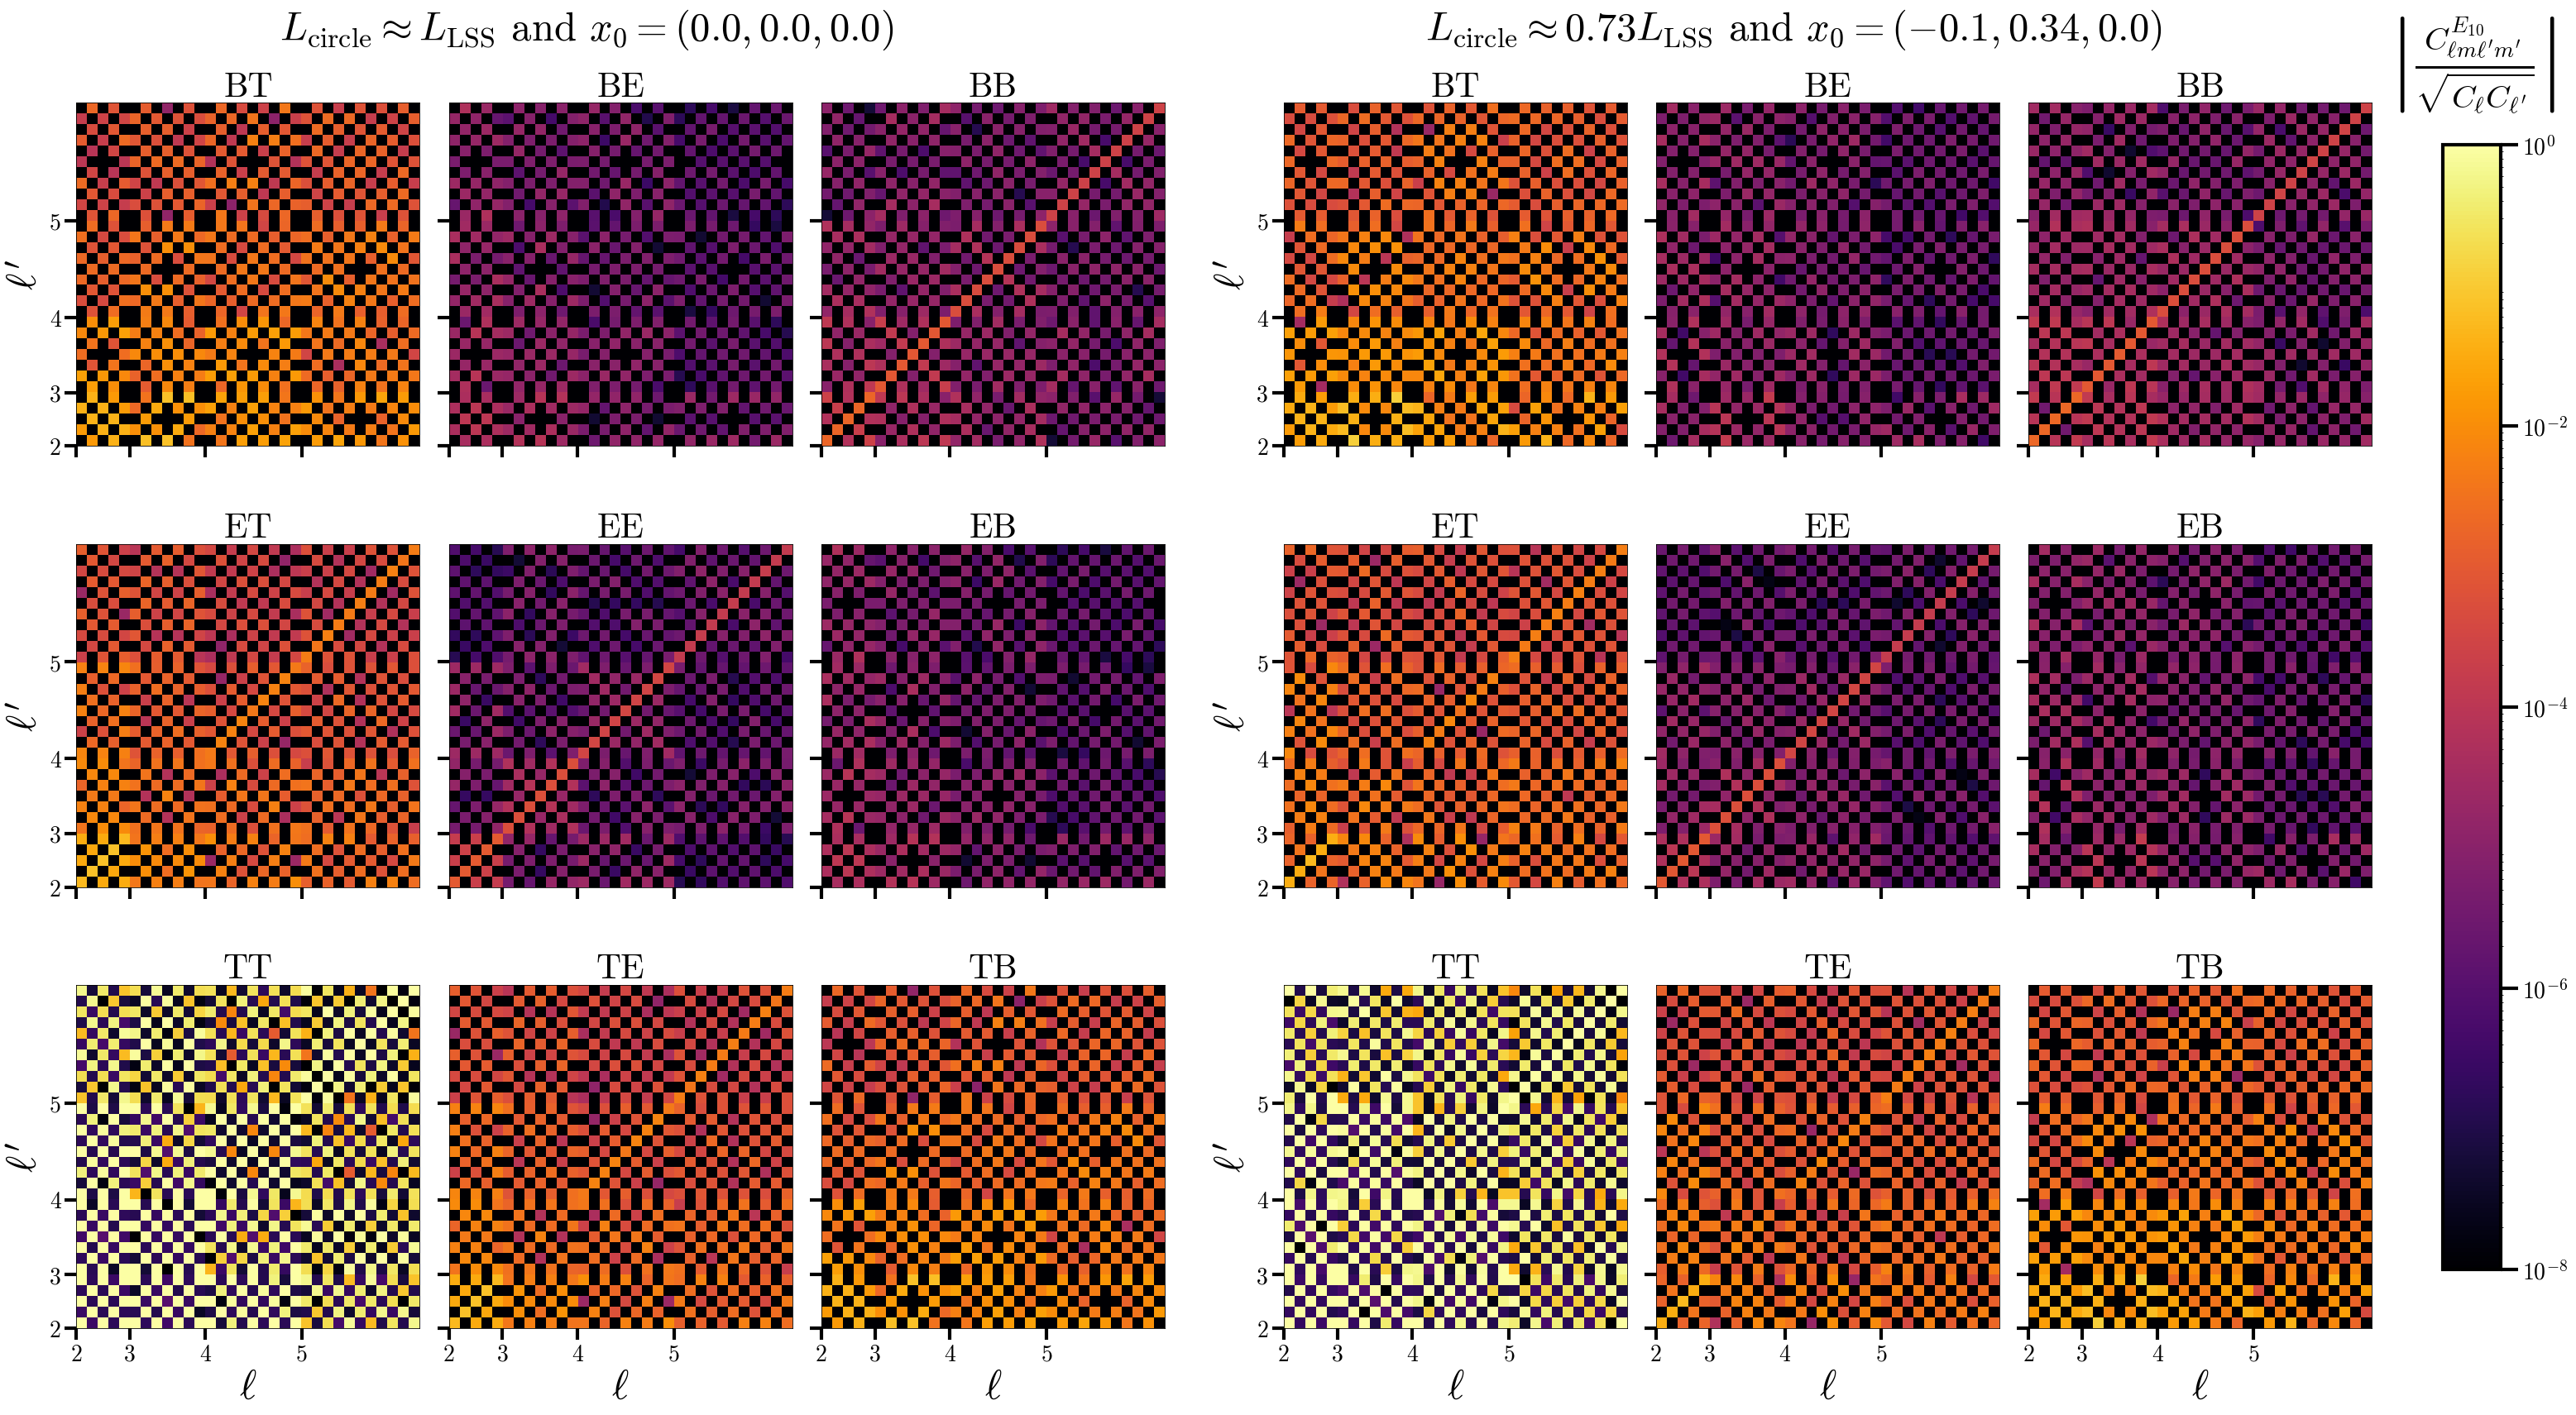

In [10]:
fig = plt.figure(figsize=(32, 17), layout='constrained')
subfig_L, subfig_R,  subfig_C = fig.subfigures(1, 3, wspace=0.05, width_ratios=[1, 1, 0.2])

axL = subfig_L.subplots(3, 3)
axR = subfig_R.subplots(3, 3)

# (title, ax_index, index into c_ell) in the same order as your original calls
panels = [('BT', 5), ('BE', 4), ('BB', 2),
          ('ET', 3), ('EE', 1), ('EB', 4),
          ('TT', 0), ('TE', 3), ('TB', 5)]

for k, (title, c_idx) in enumerate(panels):
    i, j = divmod(k, 3)
    im = do_cov_sub_plot(axL[i, j], normalize=True, title=title, ax_index=k,
                         C_order=c_ell_E10_untilted[c_idx],
                         ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))
    do_cov_sub_plot(axR[i, j], normalize=True, title=title, ax_index=k,
                    C_order=c_ell_E10_tilted[c_idx],   # <- swap in the right-hand dataset
                    ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))

subfig_L.suptitle(r'$L_{\text{circle}} \approx L_{\text{LSS}}$ and $x_0 = (0.0, 0.0, 0.0)$',
                  fontweight='bold', fontsize=35)
subfig_R.suptitle(r'$L_{\text{circle}} \approx 0.73 L_{\text{LSS}}$ and $x_0 = (-0.1, 0.34, 0.0)$',
                  fontweight='bold', fontsize=35)

# colorbar axes inside the third subfigure: [left, bottom, width, height] as fractions of subfig_C
cax = subfig_C.add_axes([0.10, 0.10, 0.25, 0.80])
cbar = subfig_C.colorbar(im, cax=cax)

cbar.ax.set_title(r"$\left| \frac{C^{E_{10}}_{\ell m \ell' m'}}{\sqrt{C_{\ell}C_{\ell'}}} \right|$", fontsize=40, pad=60)
cbar.set_ticks([1e0, 1e-2, 1e-4, 1e-6, 1e-8])
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(3)
cbar.ax.tick_params(which='major', length=15, width=3, labelsize=20)
plt.savefig('plots_E10.pdf', bbox_inches='tight', dpi=400)


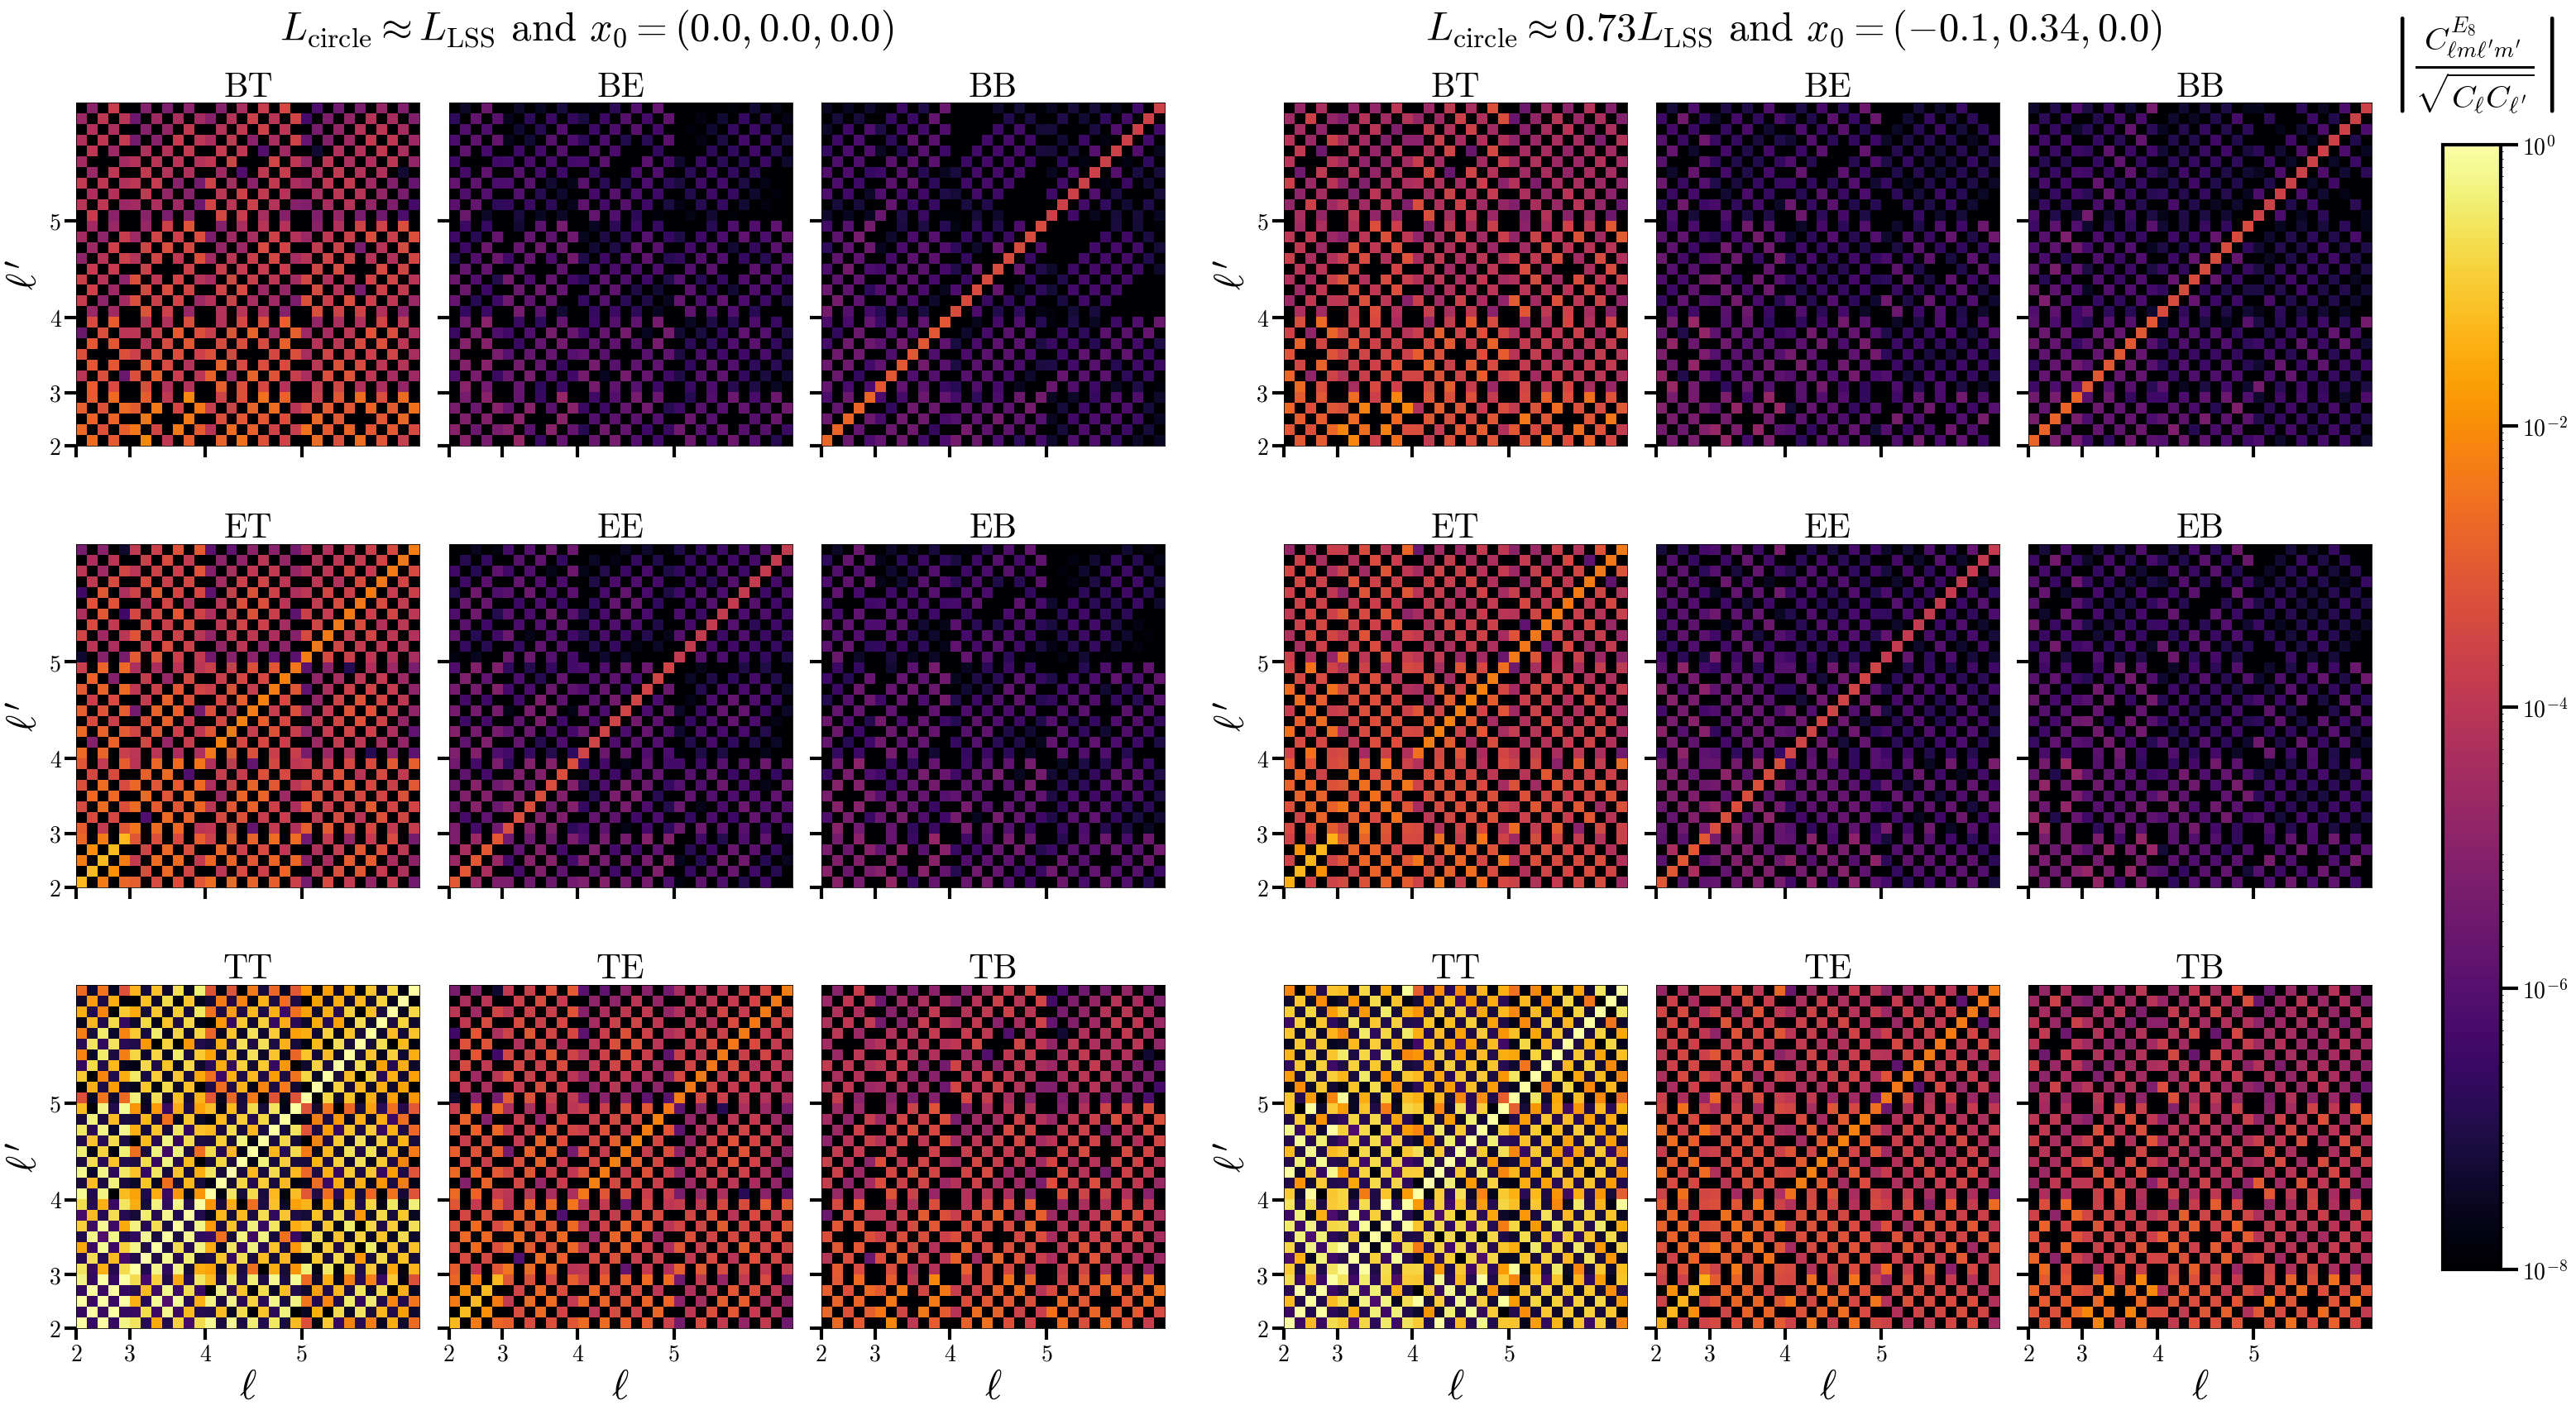

In [11]:
fig = plt.figure(figsize=(32, 17), layout='constrained')
subfig_L, subfig_R,  subfig_C = fig.subfigures(1, 3, wspace=0.05, width_ratios=[1, 1, 0.2])

axL = subfig_L.subplots(3, 3)
axR = subfig_R.subplots(3, 3)

# (title, ax_index, index into c_ell) in the same order as your original calls
panels = [('BT', 5), ('BE', 4), ('BB', 2),
          ('ET', 3), ('EE', 1), ('EB', 4),
          ('TT', 0), ('TE', 3), ('TB', 5)]

for k, (title, c_idx) in enumerate(panels):
    i, j = divmod(k, 3)
    im = do_cov_sub_plot(axL[i, j], normalize=True, title=title, ax_index=k,
                         C_order=c_ell_untilted[c_idx],
                         ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))
    do_cov_sub_plot(axR[i, j], normalize=True, title=title, ax_index=k,
                    C_order=c_ell_tilted[c_idx],   # <- swap in the right-hand dataset
                    ell_range=np.array([2, l_max]), ell_p_range=np.array([2, l_max]))

subfig_L.suptitle(r'$L_{\text{circle}} \approx L_{\text{LSS}}$ and $x_0 = (0.0, 0.0, 0.0)$',
                  fontweight='bold', fontsize=35)
subfig_R.suptitle(r'$L_{\text{circle}} \approx 0.73 L_{\text{LSS}}$ and $x_0 = (-0.1, 0.34, 0.0)$',
                  fontweight='bold', fontsize=35)

# colorbar axes inside the third subfigure: [left, bottom, width, height] as fractions of subfig_C
cax = subfig_C.add_axes([0.10, 0.10, 0.25, 0.80])
cbar = subfig_C.colorbar(im, cax=cax)

cbar.ax.set_title(r"$\left| \frac{C^{E_{8}}_{\ell m \ell' m'}}{\sqrt{C_{\ell}C_{\ell'}}} \right|$", fontsize=40, pad=60)
cbar.set_ticks([1e0, 1e-2, 1e-4, 1e-6, 1e-8])
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(3)
cbar.ax.tick_params(which='major', length=15, width=3, labelsize=20)
plt.savefig('plots_E8.pdf', bbox_inches='tight', dpi=400)


# E_15

In [ ]:
l_max = 5
L_circle = 1
L1y = 10 # This parameter need to be big

c_ell_E15_untilted = run_topology(topology = 'E8', LAx = L_circle, LAy = 0, L1y = 1.2, L2x = 0.7, L2z = 1, 
              l_max = l_max, x0= np.array([0.0, 0.0, 0.0], dtype=np.float64), 
              l_range = np.array([[2,l_max]]), lp_range = np.array([[2,l_max]]))

